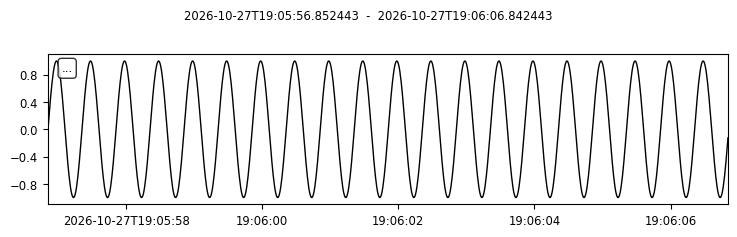

In [92]:
import numpy as np
from obspy import Trace, UTCDateTime
dt = 0.01 # delta en segundos (=> Fs = 100 Hz)
npts = 1000 # n´umero de muestras (~10 s)
t = np.arange(npts) * dt
f = 2.0
sine = np.sin(2*np.pi*f*t)
tr = Trace(sine)
tr.stats.sampling_rate = 1.0/dt
tr.stats.starttime = UTCDateTime.now()
out1 = tr.plot()

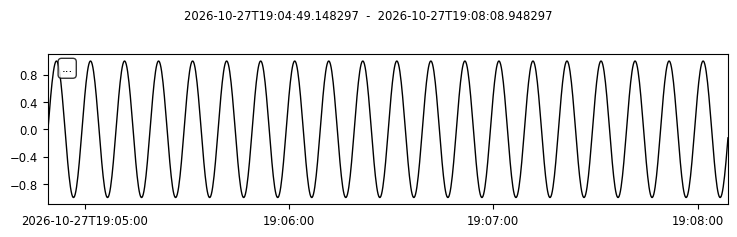

In [ ]:
import numpy as np
from obspy import Trace, UTCDateTime
dt = 0.125 # delta en segundos (=> Fs = 4 Hz) # dt = 0.1 buena aproximación, dt = 0.2 información suficiente de la señal?, dt = 0.24 ??? ¿, dt = 0,25 señal destruida
npts = 100 # n´umero de muestras (~10 s)
t = np.arange(npts) * dt
f = 2.0
sine = np.sin(2*np.pi*f*t)
tr = Trace(sine)
tr.stats.sampling_rate = 1.0/dt
tr.stats.starttime = UTCDateTime.now()
out1 = tr.plot()

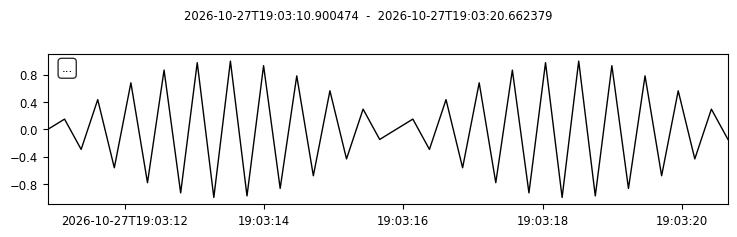

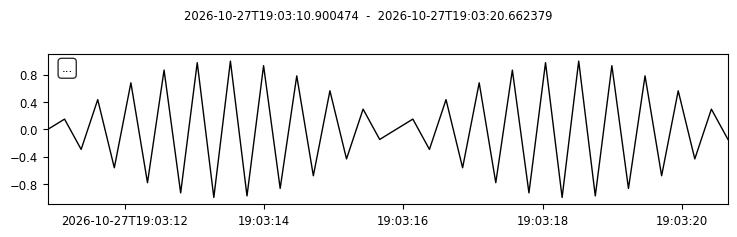

In [85]:
import numpy as np
from obspy import Trace, UTCDateTime
dt = 0.01 # delta en segundos (=> Fs = 100 Hz)
npts = 1000 # n´umero de muestras (~10 s)
t = np.arange(npts) * dt
f = 2.0
sine = np.sin(2*np.pi*f*t)
tr = Trace(sine)
tr.stats.sampling_rate = 1.0/dt
tr.stats.starttime = UTCDateTime.now()
tr.interpolate(sampling_rate=4.2, method="weighted_average_slopes")
tr.plot()

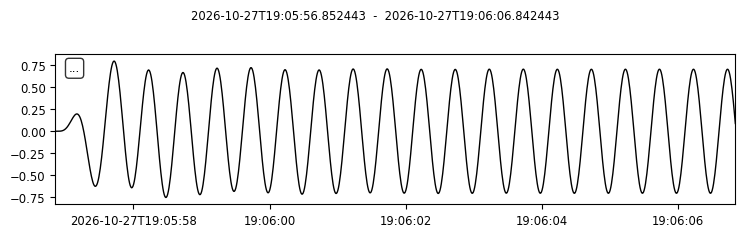

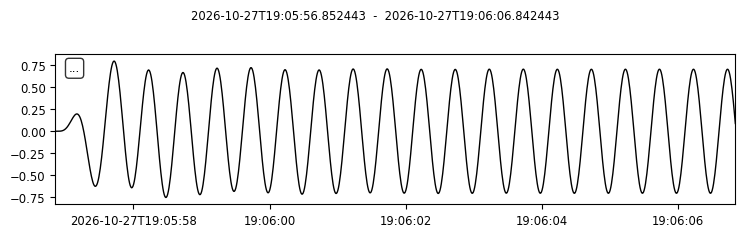

In [93]:
# filter the trace
tr.filter('bandpass', freqmin=0.5, freqmax=2, corners=4)
tr.plot()

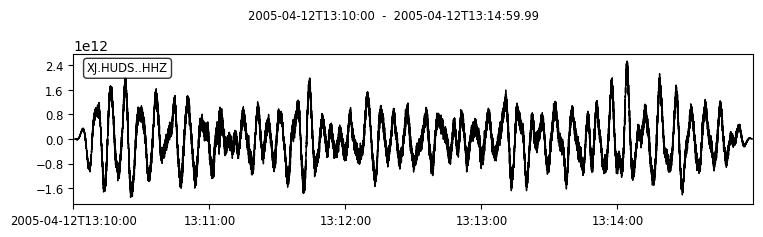

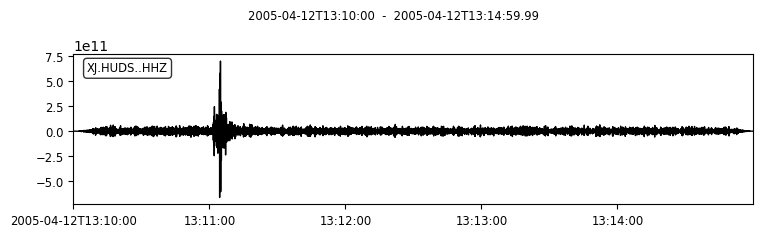

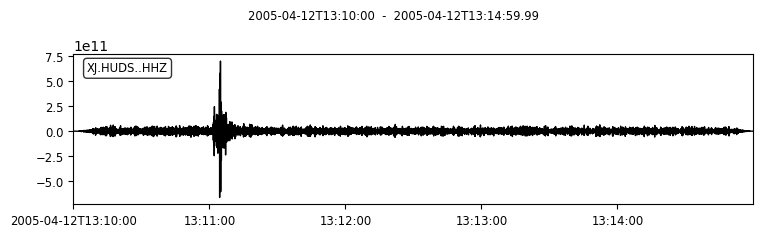

In [96]:
from obspy import read
tr = read("2005.102.13.10.00.0000.XJ.HUDS..HHZ.D.SAC")[0]
tr.detrend("demean"); tr.detrend("linear"); tr.taper(0.05, type="cosine")
tr.plot()
tr.filter('bandpass', freqmin=3, freqmax=8, corners=6)
tr.plot()

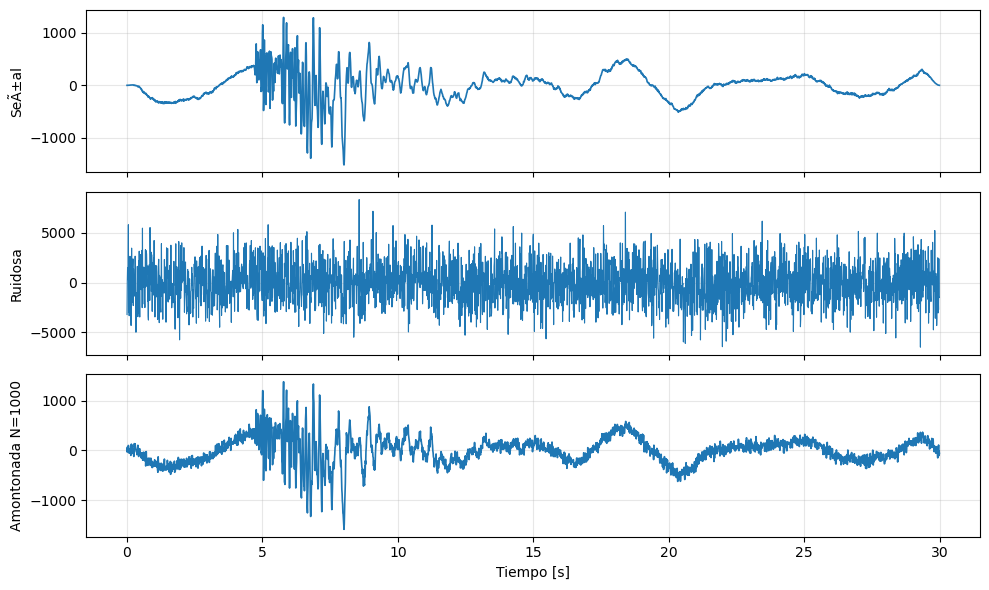

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from obspy import Trace, Stream, read, UTCDateTime

tr = read()[0]                 
t = tr.times()
signal = tr.data  

N = 1000
rng = np.random.default_rng(1234)
noise_sigma = 2000.0
st = Stream()
for k in range(N):
    noisy = signal + rng.normal(0.0, noise_sigma, size=signal.size)
    tr_noisy = Trace(noisy)
    tr_noisy.stats.sampling_rate = tr.stats.sampling_rate    
    tr_noisy.stats.starttime = tr.stats.starttime
    st.append(tr_noisy)

stack = np.mean([tr_noisy.data for tr_noisy in st], axis=0)

fig, axes = plt.subplots(3, 1, sharex=True, figsize=(10, 6))
axes[0].plot(t, signal, lw=1.2);            axes[0].set_ylabel("SeÃ±al")
axes[1].plot(t, st[0].data, lw=0.8);        axes[1].set_ylabel("Ruidosa")
axes[2].plot(t, stack, lw=1.2);             axes[2].set_ylabel(f"Amontonada N={N}")
axes[2].set_xlabel("Tiempo [s]")
for ax in axes:
    ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()